# Exploration des données de qualité de l'air

**Projet Novaria Smart City AI · Sprint 1**

Objectif : comprendre les 12 CSV du dataset *Beijing Multi-Site Air Quality* avant d'entraîner les modèles :
valeurs manquantes, doublons, incohérences, unités, distributions et saisonnalité.

Les données sont chargées et contrôlées **avec le module de préparation partagé** (`novaria.preparation`) :
le notebook observe, il ne réimplémente aucune règle. Les règles retenues sont justifiées dans `docs/preparation.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from novaria.common.config import (
    DEMO_START,
    FROZEN_SENSOR_MIN_HOURS,
    NUMERIC_MEASURES,
    POLLUTANTS,
    RAW_DATA_DIR,
    REPORTS_DIR,
    STATION_COLUMN,
    TEST_START,
    TRAIN_START,
    VAL_START,
)
from novaria.pipeline.ingestion import list_station_files, read_station_csv
from novaria.preparation.cleaning import (
    from_raw,
    frozen_sensor_runs,
    inconsistency_masks,
)
from novaria.preparation.quality import missing_hours_by_station

FIGURES = REPORTS_DIR / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 2)

## 1. Chargement et aperçu

In [2]:
raw = pd.concat([read_station_csv(p) for p in list_station_files(RAW_DATA_DIR)], ignore_index=True)
df = from_raw(raw)  # format commun : index timestamp, station_id + 12 mesures, aucune correction
print(f"{len(df):,} lignes, {df[STATION_COLUMN].nunique()} stations")
print(f"Période : {df.index.min()} -> {df.index.max()}")
df.head()

420,768 lignes, 12 stations
Période : 2013-03-01 00:00:00 -> 2017-02-28 23:00:00


,station_id,pm25,pm10,no2,co,so2,o3,temp,pres,dewp,rain,wspm,wd
timestamp,,,,,,,,,,,,,
2013-03-01,Aotizhongxin,4.0,4.0,7.0,300.0,4.0,77.0,-0.7,1023.0,-18.8,0.0,4.4,NNW
2013-03-01,Changping,3.0,6.0,7.0,300.0,13.0,85.0,-2.3,1020.8,-19.7,0.0,0.5,E
2013-03-01,Dingling,4.0,4.0,NaN,200.0,3.0,82.0,-2.3,1020.8,-19.7,0.0,0.5,E
2013-03-01,Dongsi,9.0,9.0,17.0,300.0,3.0,89.0,-0.5,1024.5,-21.4,0.0,5.7,NNW
2013-03-01,Guanyuan,4.0,4.0,20.0,300.0,14.0,69.0,-0.7,1023.0,-18.8,0.0,4.4,NNW


In [3]:
df[STATION_COLUMN].value_counts().sort_index().to_frame("lignes").T

station_id,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
lignes,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064,35064


## 2. Valeurs manquantes

Part de valeurs manquantes par station et par variable, puis leur répartition dans le temps.

Total par variable (%) :
{'pm25': 2.08, 'pm10': 1.53, 'no2': 2.88, 'co': 4.92, 'so2': 2.14, 'o3': 3.16, 'temp': 0.09, 'pres': 0.09, 'dewp': 0.1, 'rain': 0.09, 'wspm': 0.08, 'wd': 0.43}


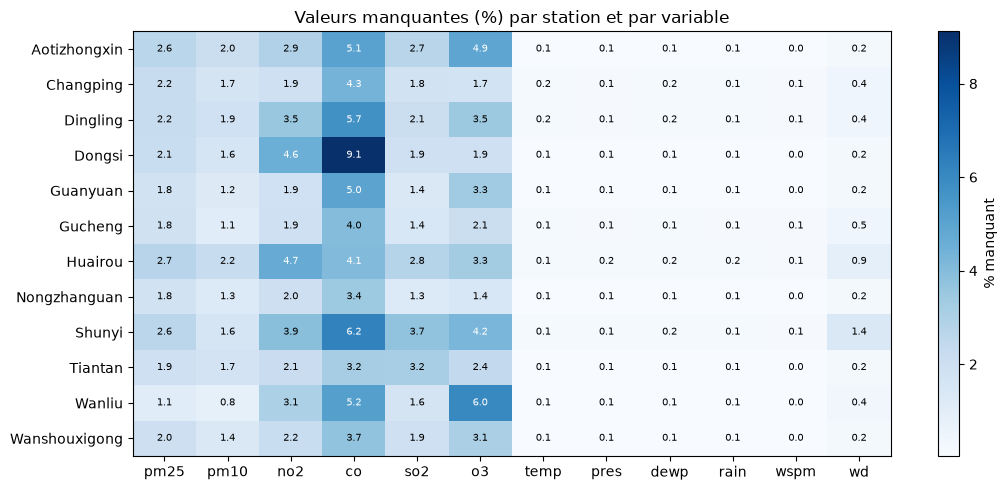

In [4]:
missing = df[[*NUMERIC_MEASURES, "wd"]].isna().groupby(df[STATION_COLUMN]).mean() * 100
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(missing.to_numpy(), cmap="Blues", aspect="auto")
ax.set_xticks(range(missing.shape[1]), missing.columns)
ax.set_yticks(range(missing.shape[0]), missing.index)
for (i, j), v in np.ndenumerate(missing.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if v > 4 else "black")
ax.grid(False)
fig.colorbar(im, label="% manquant")
ax.set_title("Valeurs manquantes (%) par station et par variable")
fig.tight_layout(); fig.savefig(FIGURES / "missing_by_station.png", dpi=120)
print("Total par variable (%) :")
print((df[[*NUMERIC_MEASURES, "wd"]].isna().mean() * 100).round(2).to_dict())

Mois les plus touchés (moyenne des polluants) :
timestamp
2014-02-01    8.3
2014-12-01    7.6
2013-07-01    6.9
2013-12-01    6.3
2016-09-01    6.1
dtype: float64


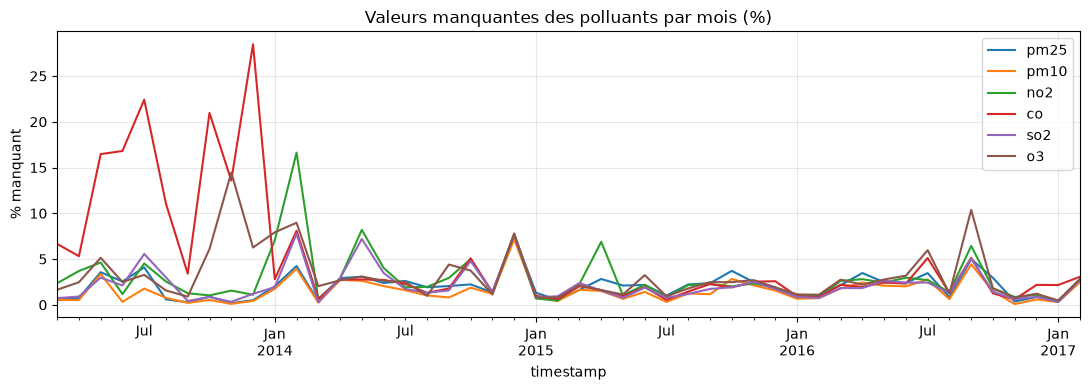

In [5]:
monthly_missing = df[POLLUTANTS].isna().resample("MS").mean() * 100
ax = monthly_missing.plot(title="Valeurs manquantes des polluants par mois (%)", ylabel="% manquant")
ax.figure.tight_layout(); ax.figure.savefig(FIGURES / "missing_by_month.png", dpi=120)
print("Mois les plus touchés (moyenne des polluants) :")
print(monthly_missing.mean(axis=1).nlargest(5).round(1))

## 3. Doublons et heures manquantes

In [6]:
dups = df.reset_index().duplicated(["timestamp", STATION_COLUMN]).sum()
print(f"Doublons (station, horodatage) : {dups}")
print(f"Heures manquantes par station : {missing_hours_by_station(df)}")

Doublons (station, horodatage) : 0


Heures manquantes par station : {'Aotizhongxin': 0, 'Changping': 0, 'Dingling': 0, 'Dongsi': 0, 'Guanyuan': 0, 'Gucheng': 0, 'Huairou': 0, 'Nongzhanguan': 0, 'Shunyi': 0, 'Tiantan': 0, 'Wanliu': 0, 'Wanshouxigong': 0}


## 4. Incohérences

Comptage des valeurs impossibles avec les règles du module (`inconsistency_masks`) :
concentrations négatives, valeurs hors bornes physiques, PM2.5 > PM10, direction de vent inconnue.

In [7]:
masks = inconsistency_masks(df)
counts = {err: {col: int(m.sum()) for col, m in by_col.items() if m.sum()} for err, by_col in masks.items()}
counts

{'valeur_negative': {},
 'hors_bornes': {'o3': 16},
 'pm25_superieur_pm10': {'pm25': 21312, 'pm10': 21312},
 'direction_inconnue': {}}

### 4.1 PM2.5 > PM10

Physiquement, PM2.5 est inclus dans PM10 : PM2.5 > PM10 est impossible. Est-ce du bruit de mesure (petit écart) ou une vraie erreur ?

21,312 lignes (5.1%) ; écart médian 19 µg/m³ ; écart < 5 % : 9.5%


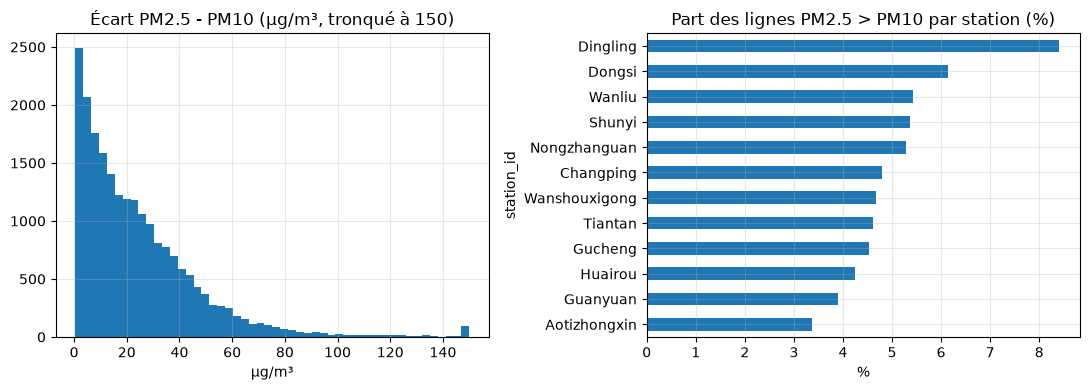

In [8]:
pm = df[df["pm25"] > df["pm10"]]
gap = pm["pm25"] - pm["pm10"]
ratio = pm["pm25"] / pm["pm10"]
print(f"{len(pm):,} lignes ({len(pm) / len(df):.1%}) ; écart médian {gap.median():.0f} µg/m³ ; "
      f"écart < 5 % : {(ratio <= 1.05).mean():.1%}")
fig, axes = plt.subplots(1, 2)
gap.clip(upper=150).hist(bins=50, ax=axes[0])
axes[0].set(title="Écart PM2.5 - PM10 (µg/m³, tronqué à 150)", xlabel="µg/m³")
(pm.groupby(STATION_COLUMN).size() / df.groupby(STATION_COLUMN).size() * 100).sort_values().plot.barh(ax=axes[1])
axes[1].set(title="Part des lignes PM2.5 > PM10 par station (%)", xlabel="%")
fig.tight_layout(); fig.savefig(FIGURES / "pm25_gt_pm10.png", dpi=120)

### 4.2 Valeurs hors bornes et saturation des capteurs

In [9]:
print("O3 > 800 µg/m³ :")
print(df.loc[df["o3"] > 800, [STATION_COLUMN, "o3", "no2", "pm25"]])
for col, cap in [("pm25", 999), ("pm10", 999), ("co", 10000), ("so2", 500)]:
    print(f"{col} = {cap} (valeur plafond) : {(df[col] == cap).sum()} lignes")

O3 > 800 µg/m³ :
                    station_id      o3    no2   pm25
timestamp                                           
2013-08-15 23:00:00     Dongsi  1071.0   40.0  195.0
2013-08-16 00:00:00     Dongsi  1071.0   34.0  203.0
2013-08-16 02:00:00     Dongsi  1050.0   19.0   64.0
2013-08-16 16:00:00     Dongsi  1026.0   69.0  193.0
2013-08-16 17:00:00     Dongsi  1071.0   65.0  206.0
2013-08-16 18:00:00     Dongsi  1071.0   85.0  207.0
2013-08-16 19:00:00     Dongsi  1071.0   86.0  187.0
2013-08-16 20:00:00     Dongsi  1071.0   98.0  202.0
2013-08-16 21:00:00     Dongsi  1071.0   95.0  202.0
2013-08-16 22:00:00     Dongsi  1071.0  102.0  198.0
2013-08-16 23:00:00     Dongsi  1071.0  118.0  201.0
2013-08-17 00:00:00     Dongsi  1071.0  101.0  197.0
2013-08-17 01:00:00     Dongsi  1071.0   75.0  168.0
2013-08-17 02:00:00     Dongsi  1071.0   97.0  161.0
2013-08-17 03:00:00     Dongsi  1071.0   70.0  164.0
2013-08-17 04:00:00     Dongsi  1071.0   58.0   66.0
pm25 = 999 (valeur plafond) :

### 4.3 Capteur figé

In [10]:
runs = frozen_sensor_runs(df, min_hours=FROZEN_SENSOR_MIN_HOURS)
print(f"Séries >= {FROZEN_SENSOR_MIN_HOURS} h : {len(runs)}")
print(runs.groupby("column")["hours"].agg(["count", "max"]))
print("\nValeurs les plus souvent figées (SO2) :")
print(runs.loc[runs["column"] == "so2", "value"].value_counts().head())

Séries >= 24 h : 1267
        count  max
column            
co         53   77
no2        20   61
o3        136   73
pm10        6   25
pm25        1   41
so2      1051  204

Valeurs les plus souvent figées (SO2) :
value
2.0    959
3.0     81
1.0     10
5.0      1
Name: count, dtype: int64


## 5. Unités

Le dataset annonce toutes les concentrations en µg/m³. Pour le CO, on attendrait souvent des mg/m³ :
on vérifie l'ordre de grandeur et le pas de mesure.

In [11]:
co = df["co"].dropna()
print(f"CO : médiane {co.median():.0f}, p99 {co.quantile(.99):.0f}, max {co.max():.0f}")
print(f"Valeurs multiples de 100 : {(co % 100 == 0).mean():.1%}")
print(f"Corrélation CO / PM2.5 : {df['co'].corr(df['pm25']):.2f}")

CO : médiane 900, p99 6000, max 10000
Valeurs multiples de 100 : 99.1%
Corrélation CO / PM2.5 : 0.79


## 6. Distributions

,count,mean,std,min,50%,99%,max,skew
pm25,412029.0,79.79,80.82,2.00,55.0,370.0,999.0,2.01
pm10,414319.0,104.60,91.77,2.00,82.0,422.0,999.0,1.89
no2,408652.0,50.64,35.13,1.03,43.0,157.0,290.0,1.05
co,400067.0,1230.77,1160.18,100.00,900.0,6000.0,10000.0,2.57
so2,411747.0,15.83,21.65,0.29,7.0,104.0,500.0,3.01
o3,407491.0,57.37,56.66,0.21,45.0,245.0,1071.0,1.66
temp,420370.0,13.54,11.44,-19.90,14.5,33.8,41.6,-0.10
pres,420375.0,1010.75,10.47,982.40,1010.4,1032.5,1042.8,0.11
dewp,420365.0,2.49,13.79,-43.40,3.1,24.5,29.1,-0.19
rain,420378.0,0.06,0.82,0.00,0.0,1.4,72.5,30.04


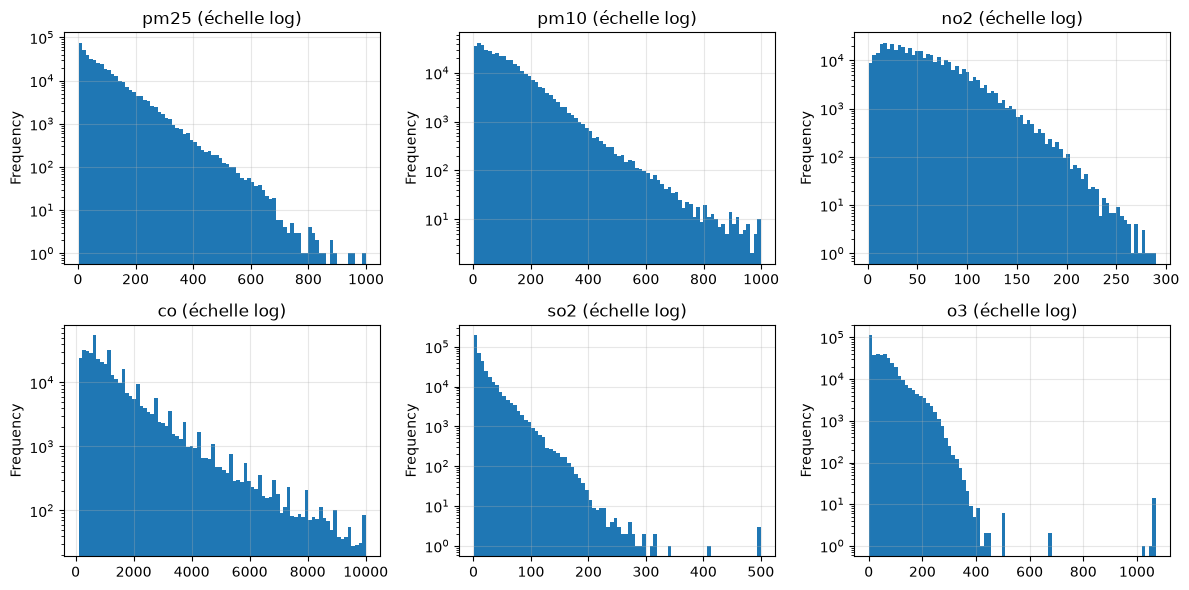

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.flat, POLLUTANTS, strict=True):
    df[col].dropna().plot.hist(bins=80, ax=ax, log=True)
    ax.set_title(f"{col} (échelle log)")
fig.tight_layout(); fig.savefig(FIGURES / "distributions.png", dpi=120)
df[NUMERIC_MEASURES].describe(percentiles=[0.5, 0.99]).T.assign(skew=df[NUMERIC_MEASURES].skew())

## 7. Saisonnalité

Moyennes mensuelles, profil journalier et profil mois × heure de PM2.5.

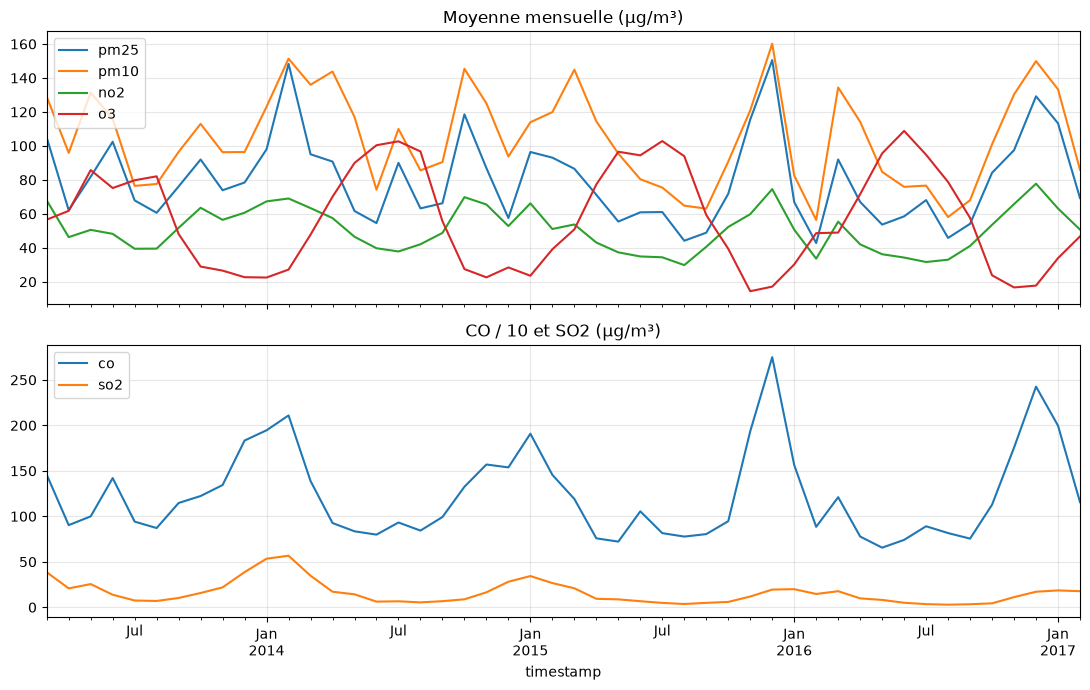

In [13]:
monthly = df[["pm25", "pm10", "no2", "co", "so2", "o3"]].resample("MS").mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
monthly[["pm25", "pm10", "no2", "o3"]].plot(ax=axes[0], title="Moyenne mensuelle (µg/m³)")
(monthly[["co"]] / 10).join(monthly[["so2"]]).plot(ax=axes[1], title="CO / 10 et SO2 (µg/m³)")
fig.tight_layout(); fig.savefig(FIGURES / "seasonality_monthly.png", dpi=120)

Médianes par saison :
           pm25   pm10   so2      co    o3
timestamp                                 
hiver      56.0   77.0  19.0  1200.0  21.0
printemps  58.0  104.0  11.0   800.0  67.0
été        51.0   70.0   3.0   800.0  78.0
automne    56.0   80.0   5.0  1000.0  21.0


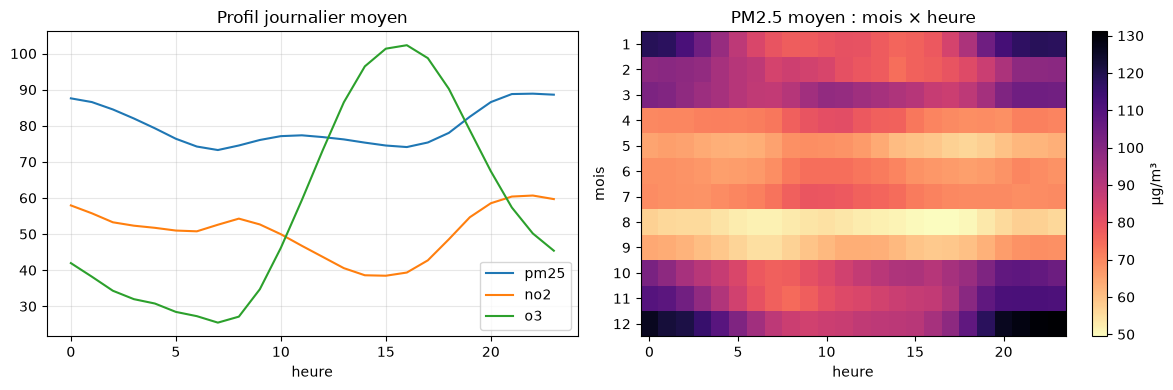

In [14]:
index = pd.DatetimeIndex(df.index)
season = pd.Series(index.month, index=df.index).map(
    {12: "hiver", 1: "hiver", 2: "hiver", 3: "printemps", 4: "printemps", 5: "printemps",
     6: "été", 7: "été", 8: "été", 9: "automne", 10: "automne", 11: "automne"})
by_season = df.groupby(season)[["pm25", "pm10", "so2", "co", "o3"]].median().loc[
    ["hiver", "printemps", "été", "automne"]]
print("Médianes par saison :")
print(by_season)
pivot = df.groupby([index.month, index.hour])["pm25"].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby(index.hour)[["pm25", "no2", "o3"]].mean().plot(ax=axes[0], title="Profil journalier moyen", xlabel="heure")
im = axes[1].imshow(pivot.to_numpy(), aspect="auto", cmap="magma_r")
axes[1].set(title="PM2.5 moyen : mois × heure", xlabel="heure", ylabel="mois")
axes[1].set_yticks(range(12), range(1, 13)); axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="µg/m³")
fig.tight_layout(); fig.savefig(FIGURES / "seasonality_profiles.png", dpi=120)

## 8. Corrélations

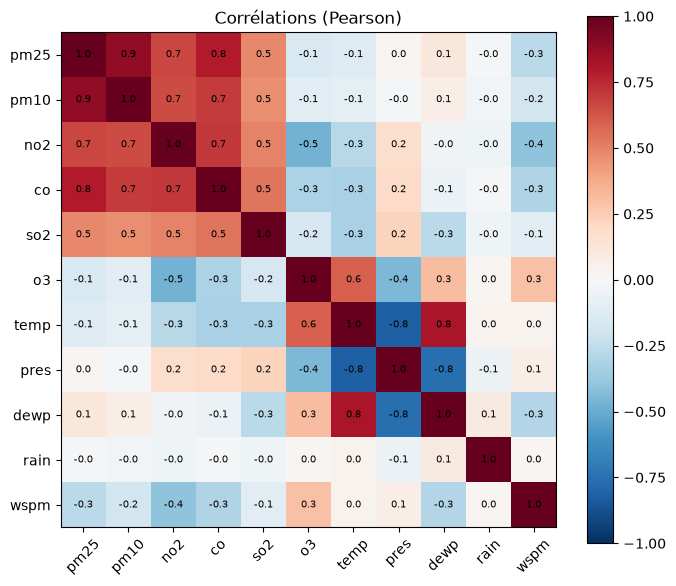

In [15]:
corr = df[NUMERIC_MEASURES].corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45); ax.set_yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7)
ax.grid(False); fig.colorbar(im)
ax.set_title("Corrélations (Pearson)")
fig.tight_layout(); fig.savefig(FIGURES / "correlations.png", dpi=120)

## 9. Découpage chronologique et dérive saisonnière

Les périodes du split (CLAUDE.md, règle 1) sur la moyenne quotidienne de PM2.5.

,pm25,co,so2,o3,temp
train,53.0,800.0,7.0,48.0,14.6
val,46.0,900.0,3.0,23.0,13.7
test,37.0,1000.0,12.0,26.0,-1.3


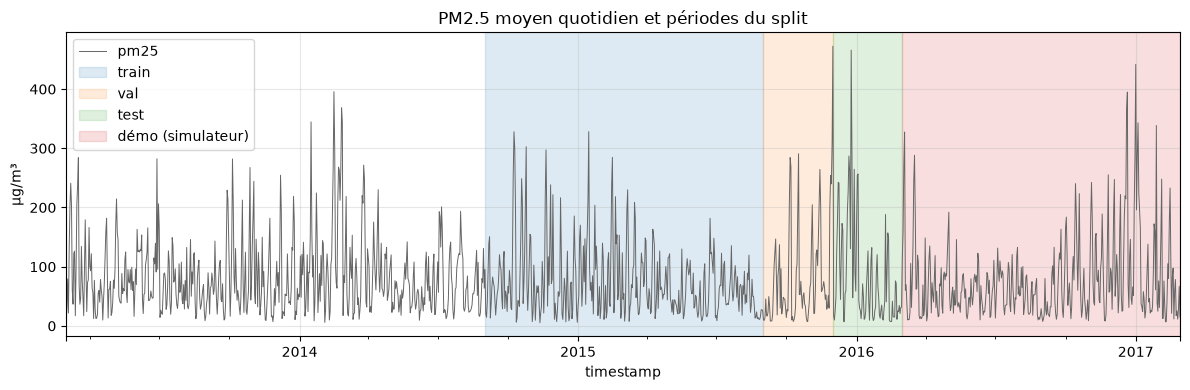

In [16]:
daily = df["pm25"].resample("D").mean()
ax = daily.plot(figsize=(12, 4), color="0.4", lw=0.7, title="PM2.5 moyen quotidien et périodes du split")
for start, end, label, color in [
    (TRAIN_START, VAL_START, "train", "tab:blue"), (VAL_START, TEST_START, "val", "tab:orange"),
    (TEST_START, DEMO_START, "test", "tab:green"), (DEMO_START, df.index.max(), "démo (simulateur)", "tab:red"),
]:
    ax.axvspan(start, end, alpha=0.15, color=color, label=label)
ax.legend(loc="upper left"); ax.set_ylabel("µg/m³")
ax.figure.tight_layout(); ax.figure.savefig(FIGURES / "split_periods.png", dpi=120)
periods = {"train": (TRAIN_START, VAL_START), "val": (VAL_START, TEST_START), "test": (TEST_START, DEMO_START)}
pd.DataFrame({name: df.loc[(df.index >= a) & (df.index < b), ["pm25", "co", "so2", "o3", "temp"]].median()
              for name, (a, b) in periods.items()}).T

## 10. Conclusions

| Constat | Chiffres | Décision (voir `docs/preparation.md`) |
|---|---|---|
| Grille horaire complète | 12 stations × 35 064 h = 420 768 lignes ; 0 doublon, 0 heure manquante | Contrôles gardés dans la préparation : ils serviront en streaming. |
| Valeurs manquantes modérées | 0,1 % (météo) à 4,9 % (CO, jusqu'à 9,1 % à Dongsi) ; pics en 2014-02 (8,3 %) et 2014-12 | Imputation médiane, ajustée sur le train, **dans le pipeline du modèle**. Limite : une valeur imputée paraît « normale ». |
| Aucune concentration négative | 0 polluant négatif ; les températures et points de rosée négatifs sont réels | Règle « négatif » gardée pour les polluants, la pluie et le vent. |
| PM2.5 > PM10 fréquent | 21 312 lignes (5,1 %), écart médian 19 µg/m³, 9,5 % seulement sous 5 % d'écart | Vraies incohérences, pas du bruit : les deux valeurs sont mises à NaN puis imputées. |
| O3 impossible | 16 valeurs > 800 µg/m³, toutes à Dongsi en août 2013, presque toutes à 1 071 (valeur bloquée) | Borne haute O3 = 800 µg/m³. |
| Plafonds de capteur | CO = 10 000 (56 lignes), PM = 999 (4 lignes) | Gardés : valeurs extrêmes mais possibles, ce sont des anomalies à détecter. |
| Capteur figé | 1 267 séries ≥ 24 h, dont 1 051 en SO2, surtout à 2 µg/m³ (seuil bas de mesure, en été) | Signalé seulement. À affiner par variable si besoin. |
| Unités | CO : médiane 900, 99,1 % de multiples de 100, corrélé à PM2.5 (0,79) | CO bien en µg/m³ (≈ 0,9 mg/m³), résolution 100 µg/m³. |
| Queues de distribution longues | Asymétrie 2 à 3 pour PM, CO, SO2 ; 30 pour la pluie | Le `StandardScaler` y est sensible : comparer avec `RobustScaler` ou un log à l'entraînement. |
| **Saisonnalité forte** | SO2 hiver 19 / été 3 (chauffage) ; O3 été 78 / hiver 21 ; PM10 printemps 104 (poussières) ; profil journalier marqué | Heure et mois en sin/cos dans les variables du modèle. |
| Dérive entre les jeux | Médianes train → test : temp 14,6 → -1,3 °C, SO2 7 → 12, O3 48 → 26 | Le train couvre une année complète. Le test n'est qu'hivernal : à rappeler dans les limites de l'évaluation. |
